# 02 · An early retirement bridged to pensions and Social Security

A worked example for the case this library was built for: a couple retires early, lives off
the portfolio for a decade, and then pensions and Social Security arrive and carry most of
the spending. The household is **fictional**:

| | |
|---|---|
| People | A and B, both 50 at the start, each planning to 95 |
| Portfolio | $1,800,000, 60% US stocks / 40% 10-year Treasuries |
| Spending | $110,000 a year, real |
| Income streams | A's pension $24,000 from 60; B's pension $9,000 from 65; A's Social Security $33,000 at full retirement age, claimed at 67; B's $26,000, claimed at 70 ($32,240 with delayed credits) |

The household is written the way you would write your own: a list of **people** and a list
of **income streams**, each with its owner, start age, cost-of-living (COLA) rule and survivor
share. The same household can live in a plan file (section 6), which the command line, the web
UI and this library all read.

All dollars are real (today's purchasing power). Each section changes one thing and reports a
small table of outcomes over every historical cohort (Shiller data, 1871 on) or, in section 5,
Monte Carlo trials.

*Educational software, not financial advice.*

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import pandas as pd

import firebridgelab as rm
from firebridgelab import IncomeStream, Person

plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (9, 4.2)})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

base = rm.with_household(
    replace(rm.default_scenario(), initial_portfolio=1_800_000.0, annual_spending=110_000.0),
    people=[Person("a", 50, 95), Person("b", 50, 95)],
    income_streams=[
        # Ages are the owner's own ages. survivor_fraction: the share that
        # continues to the survivor if the owner dies first (section 3).
        IncomeStream("a_pension", "pension", 24_000.0, 60, owner="a", survivor_fraction=0.5),
        IncomeStream("b_pension", "pension", 9_000.0, 65, owner="b", survivor_fraction=0.5),
        # Social Security: the benefit at full retirement age (67) and the claim age.
        IncomeStream("a_ss", "social_security", 33_000.0, 67, owner="a"),
        IncomeStream("b_ss", "social_security", 26_000.0, 70, owner="b"),
    ],
)
rm.validate_scenario(base)

# The same household as the library's built-in default, so the numbers match notebook 01's
# conventions and the pinned canary.
assert rm.simulate(base).final_portfolio == rm.simulate(rm.default_scenario()).final_portfolio

PENSIONS = {"a_pension", "b_pension"}

def edit_streams(s, ids, **changes):
    """A copy of scenario s with the named income streams changed."""
    return replace(s, income_streams=tuple(
        replace(st, **changes) if st.id in ids else st for st in s.income_streams))

gi = {age: rm.gi_at_age(base, age) for age in (50, 60, 65, 67, 70)}
print("Guaranteed income by age:", {a: f"${v:,.0f}" for a, v in gi.items()})

Guaranteed income by age: {50: '$0', 60: '$24,000', 65: '$33,000', 67: '$66,000', 70: '$98,240'}


The bridge is the decade before 60, when the portfolio funds the whole $110k. From 70 on,
guaranteed income covers about $98k of it.

A helper turns a result into one table row. **Depleted %** is the share of paths whose
portfolio reached zero before 95 (after which spending falls to guaranteed income).
**p10 / median end** are the 10th-percentile and median portfolio at 95. For strategies whose
spending moves, **lowest p10 spend** is the lowest 10th-percentile spending across ages, and
for guardrails **% ever at floor** is the share of paths that were ever cut to the floor.

In [2]:
def row(label, scenario, mc=False, **mc_kwargs):
    r = rm.simulate_monte_carlo(scenario, **mc_kwargs) if mc else rm.simulate_historical(scenario)
    n = r.trial_count if mc else r.cohort_count
    out = {
        "variant": label,
        "paths": n,
        "depleted %": 100 * r.depletion_count / n,
        "earliest depletion": r.earliest_depletion_age,
        "p10 end $k": r.ending_range[0] / 1e3,
        "median end $k": r.median[-1] / 1e3,
    }
    if r.spend_p10 is not None:
        out["lowest p10 spend $k"] = min(r.spend_p10) / 1e3
    if r.adjustment_stats is not None:
        out["% ever at floor"] = 100 * r.adjustment_stats.pct_ever_forced_to_floor
        out["median yrs at floor"] = r.adjustment_stats.median_years_at_floor
    return out

def table(rows):
    df = pd.DataFrame(rows).set_index("variant").round(1)
    df["earliest depletion"] = df["earliest depletion"].astype("Int64")
    return df

## 1. Spending rules: constant, guardrails, amortization frontier

- **Constant**: $110k every year, whatever the markets do.
- **Guardrails** (`spending_mode="guardrails"`): a Guyton-Klinger-style rule applied to the
  withdrawal rate *net of guaranteed income*. When the net rate drifts 20% above its starting
  level spending is cut 10%, when it drifts 20% below spending rises 10%, always within a
  floor ($85k) and ceiling ($150k). Netting matters for a bridge: the gross withdrawal rate in
  the bridge years looks alarming even when the plan is fine, because the pensions are coming.
- **Amortization frontier** (`spending_mode="amortization"`): each year, the constant real
  spend that would run the portfolio to exactly zero at 95 given the guaranteed income still
  to come, discounted at a conservative 1% real. It is a maximum-consumption benchmark, not
  a recommendation.

In [3]:
rules = table([
    row("constant", base),
    row("guardrails", replace(base, spending_mode="guardrails")),
    row("amortization frontier", replace(base, spending_mode="amortization")),
])
rules

,paths,depleted %,earliest depletion,p10 end $k,median end $k,lowest p10 spend $k,% ever at floor,median yrs at floor
variant,,,,,,,,
constant,110,15.5,63,0.0,3721.2,NaN,NaN,NaN
guardrails,110,0.0,<NA>,1495.6,2727.9,85.0,36.4,0.0
amortization frontier,110,32.7,95,0.0,1.8,99.5,6.4,0.0


Guardrails remove depletion in every historical cohort here, at the cost of being cut to
the $85k floor at some point in about a third of them. The amortization frontier spends the
most early and is built to finish at zero: its "depletions" are cohorts that reach zero in the
final year, which is the rule working as designed, not a failure.

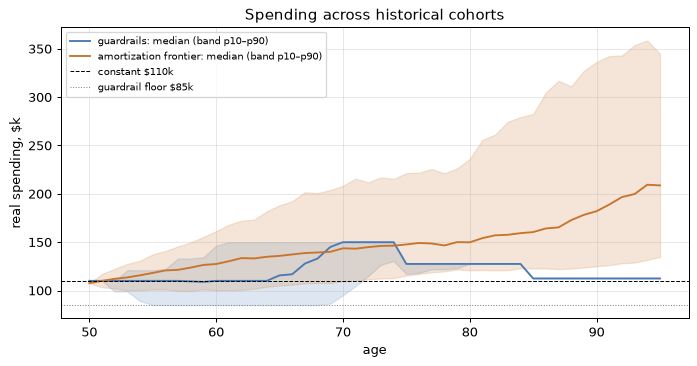

In [4]:
g = rm.simulate_historical(replace(base, spending_mode="guardrails"))
a = rm.simulate_historical(replace(base, spending_mode="amortization"))
fig, ax = plt.subplots()
for res, name, color in ((g, "guardrails", "#4a7ab5"), (a, "amortization frontier", "#c8742c")):
    ax.fill_between(res.ages, [v / 1e3 for v in res.spend_p10], [v / 1e3 for v in res.spend_p90],
                    alpha=0.18, color=color)
    ax.plot(res.ages, [v / 1e3 for v in res.spend_median], color=color, label=f"{name}: median (band p10–p90)")
ax.axhline(110, color="black", lw=0.8, ls="--", label="constant $110k")
ax.axhline(base.spending_floor / 1e3, color="gray", lw=0.8, ls=":", label="guardrail floor $85k")
ax.set_xlabel("age"); ax.set_ylabel("real spending, $k")
ax.set_title("Spending across historical cohorts")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

## 2. FERS-style pension options

Many defined-benefit pensions are not fully indexed. Two stream options model a FERS-style
deferred annuity:

- `nominal_until_start=True`: the amount is the **nominal** check at commencement. Between
  the plan start and commencement it loses value to inflation (`assumed_inflation`, 2.5% by
  default), so the real value at start is smaller.
- `cola="fers_diet"`: after commencement the COLA is CPI if CPI ≤ 2%, 2% if CPI is between
  2% and 3%, and CPI − 1% above 3% (evaluated at `assumed_inflation`). As FERS rules
  require, there is no COLA before the owner's 62, so A's pension from 60 is a fixed
  nominal check for its first two years (`fers_cola_before_62=True` is for the
  disability and special-provision retirees who do get COLAs earlier). The other choices are
  `"full"` (the default), `"none"` and `"fixed"` with a `cola_rate`.

Both are set per stream, so one pension can be FERS-style and another fully indexed. Here both
pensions change together. The first table shows the real value of the two pensions; the second
shows the effect on the plan.

In [5]:
def pensions_only(s):
    return replace(s, income_streams=tuple(st for st in s.income_streams if st.kind == "pension"))

pension_variants = {
    "indexed (default)": base,
    "nominal until start": edit_streams(base, PENSIONS, nominal_until_start=True),
    "nominal + fers_diet COLA": edit_streams(base, PENSIONS, nominal_until_start=True, cola="fers_diet"),
    "nominal + fers_diet, 4% inflation": replace(
        edit_streams(base, PENSIONS, nominal_until_start=True, cola="fers_diet"),
        assumed_inflation=0.04),
}
pd.DataFrame({
    name: {f"age {age}": round(rm.gi_at_age(pensions_only(s), age)) for age in (60, 65, 75, 85, 95)}
    for name, s in pension_variants.items()
}).T

,age 60,age 65,age 75,age 85,age 95
indexed (default),24000,33000,33000,33000,33000
nominal until start,18749,24963,24963,24963,24963
nominal + fers_diet COLA,18749,23800,22664,21582,20552
"nominal + fers_diet, 4% inflation",16214,19559,17758,16123,14638


In [6]:
table([row(name, s) for name, s in pension_variants.items()])

,paths,depleted %,earliest depletion,p10 end $k,median end $k
variant,,,,,
indexed (default),110,15.5,63,0.0,3721.2
nominal until start,110,18.2,63,0.0,3039.7
nominal + fers_diet COLA,110,21.8,63,0.0,2836.1
"nominal + fers_diet, 4% inflation",110,26.4,63,0.0,2423.4


## 3. Survivor case

`survivor_age` sets the age at which one spouse (`survivor_decedent`) dies, in that person's
own age. From then on the survivor keeps the larger of their own Social Security benefit and
the widow(er)'s benefit on the decedent's record, which is reduced if the survivor takes it
before full retirement age (to 79.6% of the decedent's benefit at 62) and starts no earlier
than the survivor's 60. Each of the
decedent's other streams continues at its `survivor_fraction` (50% for both pensions here),
spending scales by `survivor_spending_fraction` (75%), and federal tax, when modeled, switches
to single-filer brackets.

In [7]:
table([
    row("both live to 95", base),
    row("B dies at 75", replace(base, survivor_age=75, survivor_decedent="b")),
    row("A dies at 75", replace(base, survivor_age=75, survivor_decedent="a")),
    row("A dies at 62 (pension 50%, no SS yet)", replace(base, survivor_age=62, survivor_decedent="a")),
])

,paths,depleted %,earliest depletion,p10 end $k,median end $k
variant,,,,,
both live to 95,110,15.5,63,0.0,3721.2
B dies at 75,110,17.3,63,0.0,3397.2
A dies at 75,110,17.3,63,0.0,3134.1
"A dies at 62 (pension 50%, no SS yet)",110,10.0,66,50.1,3624.6


Losing Person A leaves a smaller median estate than losing Person B, because A has the
larger pension and it drops to half. A death at 62 depletes less often than one at 75 in
this replay: spending falls to 75% for 33 years instead of 20, which outweighs the lost
income, even though B, widowed at 62, takes a widow(er)'s benefit reduced for age until B's
own larger benefit starts at 70. The survivor case is mostly an income question; the table shows its size.

## 4. Fees

`annual_fee` is the all-in cost (fund expenses plus advice) as a fraction of assets, netted
from each year's real return: `r_net = (1 + r)(1 − fee) − 1`.

In [8]:
table([row(f"fee {f:.2%}", replace(base, annual_fee=f)) for f in (0.0, 0.0005, 0.0025, 0.0075, 0.01)])

,paths,depleted %,earliest depletion,p10 end $k,median end $k
variant,,,,,
fee 0.00%,110,15.5,63,0.0,3721.2
fee 0.05%,110,15.5,63,0.0,3597.9
fee 0.25%,110,17.3,63,0.0,3118.6
fee 0.75%,110,20.0,62,0.0,2087.2
fee 1.00%,110,24.5,62,0.0,1715.2


## 5. Monte Carlo with fat tails

Monte Carlo draws each year's real return per asset class, correlated, with the same mean and
volatility as the history. `mc_distribution="student_t"` swaps the Normal for a multivariate
Student-t (`mc_t_df=5` degrees of freedom), rescaled to the same mean, volatility and
correlation, so only the tails change. 10,000 trials, fixed seed.

In [9]:
table([
    row("Normal, constant", base, mc=True),
    row("Student-t df=5, constant", replace(base, mc_distribution="student_t"), mc=True),
    row("Student-t df=3, constant", replace(base, mc_distribution="student_t", mc_t_df=3.0), mc=True),
    row("Student-t df=5, guardrails", replace(base, mc_distribution="student_t", spending_mode="guardrails"), mc=True),
])

,paths,depleted %,earliest depletion,p10 end $k,median end $k,lowest p10 spend $k,% ever at floor,median yrs at floor
variant,,,,,,,,
"Normal, constant",10000,8.5,57,229.3,5807.5,NaN,NaN,NaN
"Student-t df=5, constant",10000,8.4,51,238.9,5916.5,NaN,NaN,NaN
"Student-t df=3, constant",10000,7.6,52,461.2,6506.7,NaN,NaN,NaN
"Student-t df=5, guardrails",10000,1.1,51,1100.7,4828.8,85.0,25.2,0.0


Fat tails at the **same** volatility put more weight on extreme years and also more weight
near the mean, so the depletion rate need not rise. What does change is the shape of the bad
outcomes: the earliest depletion moves into the first years of the bridge.

Monte Carlo has no autocorrelation: it cannot produce a 1966-style decade of poor real
returns as often as history did, which is one reason its depletion rates differ from the
historical replay. Its fixed seed gives roughly ±0.5 point of sampling noise on the
depletion rate.

## What to take from this

- For this household the risk sits in the bridge decade. Once the pensions and Social
  Security arrive, they cover most of the spending.
- A guardrail rule netted against guaranteed income trades occasional cuts for a much lower
  chance of running out. The table shows how often, and how deep, the cuts are.
- Pension indexing terms matter. A non-indexed pension is worth noticeably less in real
  terms by the time it starts.
- Fees compound over 45 years. 1% a year is visible in both depletion and the median estate.

## 6. Your own household, in a plan file

A plan file is a short [TOML](https://toml.io) text file that holds everything above. The
command line runs it (`firebridgelab run plan.toml`), the web UI loads and downloads it, and
`firebridgelab.plan` reads and writes it here. `dump` writes any scenario out with every value
explicit:

In [10]:
from firebridgelab import plan as planfile

text = planfile.dump(base)
print(text[: text.index("[portfolio]")])   # the household part
# Reading the text back gives the same plan.
assert rm.simulate(planfile.loads(text).scenario).final_portfolio == rm.simulate(base).final_portfolio

# firebridgelab plan file (docs/plan-files.md).

[[people]]
id = "a"
start_age = 50
end_age = 95

[[people]]
id = "b"
start_age = 50
end_age = 95

[[income_streams]]
id = "a_pension"
kind = "pension"
owner = "a"
amount = 24_000
start_age = 60
cola = "full"
survivor_fraction = 0.5

[[income_streams]]
id = "b_pension"
kind = "pension"
owner = "b"
amount = 9000
start_age = 65
cola = "full"
survivor_fraction = 0.5

[[income_streams]]
id = "a_ss"
kind = "social_security"
owner = "a"
amount = 33_000
start_age = 67
cola = "full"

[[income_streams]]
id = "b_ss"
kind = "social_security"
owner = "b"
amount = 26_000
start_age = 70
cola = "full"




The bundled examples are plan files too (`firebridgelab init --list`). `part-time-bridge`
is a couple with a two-year age gap: Sam consults part time until 55, both pay marketplace
health insurance until Medicare (required spending the spending rule cannot cut), a roof is
replaced at 60 (a cash event), and the portfolio is split across taxable, tax-deferred and Roth
accounts so federal tax is modeled. Changing a key works as on the command line's `--set`:

In [11]:
from importlib import resources

# The bundled examples ship inside the package (firebridgelab/examples/).
doc = planfile.read_document(resources.files("firebridgelab") / "examples" / "part-time-bridge.toml")
bridge = planfile.from_document(doc).scenario
print({p.id: (p.name, p.start_age, p.end_age) for p in bridge.people})
print([(st.id, st.kind, st.owner, st.amount, st.start_age, st.end_age) for st in bridge.income_streams])

def consulting_until(end_age):
    d = {**doc, "income_streams": [dict(st) for st in doc["income_streams"]]}
    planfile.apply_override(d, "income_streams.sam_consulting.end_age", end_age)
    return planfile.from_document(d).scenario

table([row(f"consulting until {e}", consulting_until(e)) for e in (50, 53, 55, 58)])

{'a': ('Sam', 48, 95), 'b': ('Riley', 46, 95)}
[('sam_consulting', 'work', 'a', 40000.0, 48, 55), ('sam_ss', 'social_security', 'a', 26000.0, 67, None), ('riley_ss', 'social_security', 'b', 20000.0, 67, None)]


,paths,depleted %,earliest depletion,p10 end $k,median end $k
variant,,,,,
consulting until 50,106,36.8,60,0.0,1791.2
consulting until 53,106,25.5,62,0.0,2685.7
consulting until 55,106,20.8,63,0.0,3335.7
consulting until 58,106,11.3,65,0.0,4068.5


Each extra year of part-time work shortens the bridge the portfolio has to carry alone. Notebook
04 runs this kind of what-if systematically: retirement age, spending, claim ages, pension COLA
rules and part-time years, with tables and charts.